In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

## 1. Data preparation

In [3]:
iris = load_iris()
X, y = iris.data, iris.target
class_names = iris.target_names

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler().fit(X_tr)               # fit on training data only
X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)
print(X_tr.shape, X_te.shape)

(120, 4) (30, 4)


## 2. Model factory
Integer labels are used, so the loss is `sparse_categorical_crossentropy`.

In [4]:
def build_mlp(hidden, activation, n_features=4, n_classes=3):
    net = models.Sequential([layers.Input(shape=(n_features,))])
    for units in hidden:
        net.add(layers.Dense(units, activation=activation))
    net.add(layers.Dense(n_classes, activation="softmax"))
    net.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return net

## 3. Grid of experiments

In [5]:
architectures = {"1x8": [8], "2x(16,8)": [16, 8], "3x(32,16,8)": [32, 16, 8]}
activations = ["relu", "tanh", "sigmoid"]

records, histories, trained = [], {}, {}
for arch_name, hidden in architectures.items():
    for act in activations:
        net = build_mlp(hidden, act)
        hist = net.fit(X_tr, y_tr, epochs=50, batch_size=5, validation_split=0.1, verbose=0)
        loss, acc = net.evaluate(X_te, y_te, verbose=0)
        key = (arch_name, act)
        histories[key], trained[key] = hist.history, net
        records.append({"architecture": arch_name, "activation": act,
                        "test_loss": round(loss, 4), "test_acc": round(acc, 4)})

results = pd.DataFrame(records).sort_values("test_acc", ascending=False).reset_index(drop=True)
results

,architecture,activation,test_loss,test_acc
0,"2x(16,8)",relu,0.1243,0.9667
1,"3x(32,16,8)",tanh,0.0868,0.9667
2,"3x(32,16,8)",relu,0.0882,0.9667
3,"2x(16,8)",tanh,0.1288,0.9333
4,1x8,tanh,0.2807,0.9000
5,1x8,relu,0.2654,0.8667
6,"3x(32,16,8)",sigmoid,0.4392,0.8667
7,"2x(16,8)",sigmoid,0.4508,0.8333
8,1x8,sigmoid,0.4594,0.8000


## 4. Learning curves for the best configuration

Best: ('2x(16,8)', 'relu')


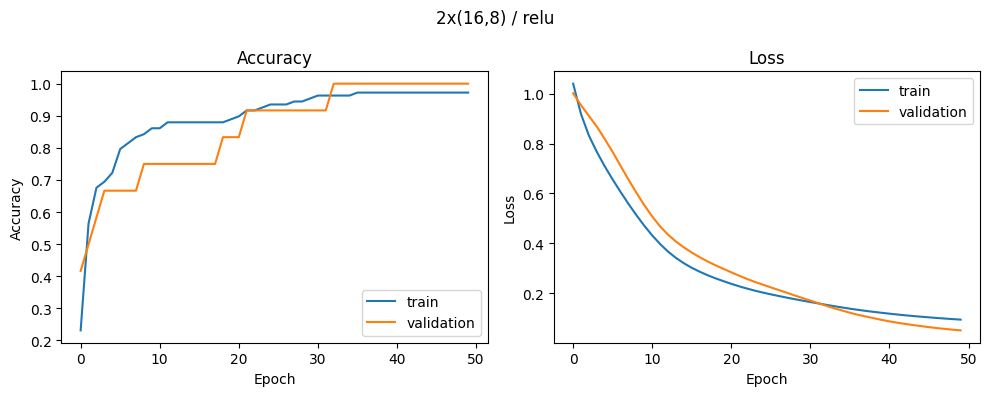

In [6]:
best = results.iloc[0]
best_key = (best["architecture"], best["activation"])
h = histories[best_key]
print("Best:", best_key)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(h["accuracy"], label="train"); ax1.plot(h["val_accuracy"], label="validation")
ax1.set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy"); ax1.legend()
ax2.plot(h["loss"], label="train"); ax2.plot(h["val_loss"], label="validation")
ax2.set(xlabel="Epoch", ylabel="Loss", title="Loss"); ax2.legend()
fig.suptitle(f"{best_key[0]} / {best_key[1]}"); plt.tight_layout(); plt.show()

## 5. Predict a single flower with the best model

In [7]:
sample = np.array([[5.1, 3.5, 1.4, 0.2]])       # sepal L/W, petal L/W (cm)
probs = trained[best_key].predict(scaler.transform(sample), verbose=0)[0]
print("Class probabilities:", dict(zip(class_names, probs.round(3))))
print("Predicted species:", class_names[probs.argmax()])

Class probabilities: {np.str_('setosa'): np.float32(0.997), np.str_('versicolor'): np.float32(0.003), np.str_('virginica'): np.float32(0.0)}
Predicted species: setosa
